# Data Mining Lab Assignment 2
## Book Recommender System with a Medallion Data Lake

**Name:** Priyanshu Agarwal
**Roll number:** LIT2023022

This notebook moves the Book-Crossing dataset through three data lake layers. Then it uses the last layer to recommend books to a user.

| Layer | Folder | Content |
|---|---|---|
| Bronze | `bronze/` | The three source tables, not changed, plus an ingestion timestamp |
| Silver | `silver/` | Clean tables |
| Gold | `gold/` | Sparse user-book rating matrix, book lookup table, user and book aggregates |

The recommender uses item-based collaborative filtering with cosine similarity.

**How to run:** open t
| Layer | Folder | Content |
|---|---|---|
| Bronze | `bronze/` | The three source tables, not changed, plus an ingestion timestamp |
| Silver | `silver/` | Clean tables |


## Setup

In [1]:
import os
import re
import html
import zipfile
import urllib.request
from collections import defaultdict
from datetime import datetime
from itertools import islice

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)

CURRENT_YEAR = datetime.now().year
print("pandas", pd.__version__, "| numpy", np.__version__, "| current year:", CURRENT_YEAR)

pandas 2.2.3 | numpy 2.2.1 | current year: 2026


## Step 1: Set up the data lake and build the Bronze layer

Create the `bronze/`, `silver/` and `gold/` folders. Download the zip file and extract the three CSV files into `raw/`.

In [2]:
for folder in ["raw", "bronze", "silver", "gold"]:
    os.makedirs(folder, exist_ok=True)

DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ZIP_PATH = "raw/book-crossings.zip"

if not os.path.exists(ZIP_PATH):
    # The server refuses Python's default user agent (HTTP 403), so send a browser one.
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response, open(ZIP_PATH, "wb") as f:
        f.write(response.read())

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("raw")
    for info in z.infolist():
        print(f"{info.filename:22s} {info.file_size / 1e6:5.1f} MB")

print("Data lake folders:", [f for f in ["bronze", "silver", "gold"] if os.path.isdir(f)])

BX-Book-Ratings.csv     30.7 MB
BX-Books.csv            77.8 MB
BX-Users.csv            12.3 MB
Data lake folders: ['bronze', 'silver', 'gold']


The files use semicolons, not commas, and the text is not UTF-8. The cell below shows what happens with the default read options.

In [3]:
RAW_FILES = {
    "users": "raw/BX-Users.csv",
    "books": "raw/BX-Books.csv",
    "ratings": "raw/BX-Book-Ratings.csv",
}

# Try 1: default options (comma separator, UTF-8).
try:
    pd.read_csv(RAW_FILES["books"])
except Exception as error:
    print("Default options      ->", type(error).__name__ + ":", str(error).strip()[:100])

# Try 2: semicolon separator and Latin-1 encoding, but no escape character.
try:
    pd.read_csv(RAW_FILES["books"], sep=";", encoding="latin-1")
except Exception as error:
    print("Semicolon + Latin-1  ->", type(error).__name__ + ":", str(error).strip())

with open(RAW_FILES["books"], encoding="latin-1") as f:
    line_6452 = next(islice(f, 6451, None))
print("\nLine 6452 of BX-Books.csv (the title contains \\\"):")
print(line_6452[:140])

Default options      -> UnicodeDecodeError: 'utf-8' codec can't decode byte 0xc3 in position 9431: invalid continuation byte
Semicolon + Latin-1  -> ParserError: Error tokenizing data. C error: Expected 8 fields in line 6452, saw 9

Line 6452 of BX-Books.csv (the title contains \"):
"0735201994";"Peterman Rides Again: Adventures Continue with the Real \"J. Peterman\" Through Life &amp; the Catalog Business";"John Peterma


Read options for the Bronze layer:

- `sep=";"`: the separator is a semicolon.
- `encoding="latin-1"`: the files use Latin-1 (ISO-8859-1) text, not UTF-8.
- `escapechar="\\"`: some titles contain `\"`. Without this option, the read fails at line 6452 (see above).
- `dtype=str`: keep every value as text, exactly as it is in the file. This also keeps the leading zeros in ISBNs.
- `keep_default_na=False, na_values=["NULL", ""]`: only the file's own `NULL` markers and empty fields become missing values.

This layer does not clean, drop or change any row. pandas uses `on_bad_lines="error"` by default, so it stops at a bad line and does not skip it.

In [4]:
READ_OPTIONS = dict(
    sep=";",
    encoding="latin-1",
    escapechar="\\",
    dtype=str,
    keep_default_na=False,
    na_values=["NULL", ""],
)

ingestion_timestamp = pd.Timestamp.now(tz="UTC")

for name, path in RAW_FILES.items():
    table = pd.read_csv(path, **READ_OPTIONS)
    table["ingestion_timestamp"] = ingestion_timestamp
    table.to_parquet(f"bronze/{name}.parquet", index=False)
    print(f"bronze/{name}.parquet: {table.shape[0]:,} rows x {table.shape[1]} columns")
    display(table.head(3))

bronze/users.parquet: 278,858 rows x 4 columns


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NaN,2026-11-26 11:37:25.054880+00:00
1,2,"stockton, california, usa",18,2026-11-26 11:37:25.054880+00:00
2,3,"moscow, yukon territory, russia",NaN,2026-11-26 11:37:25.054880+00:00


bronze/books.parquet: 271,379 rows x 9 columns


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg,2026-11-26 11:37:25.054880+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg,2026-11-26 11:37:25.054880+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ.jpg,2026-11-26 11:37:25.054880+00:00


bronze/ratings.parquet: 1,149,780 rows x 4 columns


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-26 11:37:25.054880+00:00
1,276726,0155061224,5,2026-11-26 11:37:25.054880+00:00
2,276727,0446520802,0,2026-11-26 11:37:25.054880+00:00


## Step 2: Explore the Bronze data (EDA)

Read the Bronze tables back from Parquet. Each check ends with one line: what I found, and what I will do about it in Silver.

In [5]:
users_b = pd.read_parquet("bronze/users.parquet")
books_b = pd.read_parquet("bronze/books.parquet")
ratings_b = pd.read_parquet("bronze/ratings.parquet")
bronze = {"users": users_b, "books": books_b, "ratings": ratings_b}

# Numeric copies for the EDA only. The Bronze tables stay as text.
age_b = pd.to_numeric(users_b["Age"], errors="coerce")
year_b = pd.to_numeric(books_b["Year-Of-Publication"], errors="coerce")
rating_b = pd.to_numeric(ratings_b["Book-Rating"], errors="coerce")

### 2.1 Shape, data types and missing values

In [6]:
for name, table in bronze.items():
    print(f"{name}: {table.shape[0]:,} rows x {table.shape[1]} columns")
    display(pd.DataFrame({
        "dtype": table.dtypes.astype(str),
        "missing": table.isna().sum(),
        "missing %": (table.isna().mean() * 100).round(2),
    }))

# Can the numeric columns be read as numbers?
for name, column in [("users", "User-ID"), ("users", "Age"), ("books", "Year-Of-Publication"),
                     ("ratings", "User-ID"), ("ratings", "Book-Rating")]:
    values = bronze[name][column]
    not_numeric = values.notna() & pd.to_numeric(values, errors="coerce").isna()
    print(f"{name}.{column}: {not_numeric.sum()} values are not numbers")

users: 278,858 rows x 4 columns


,dtype,missing,missing %
User-ID,object,0,0.00
Location,object,0,0.00
Age,object,110762,39.72
ingestion_timestamp,"datetime64[us, UTC]",0,0.00


books: 271,379 rows x 9 columns


,dtype,missing,missing %
ISBN,object,0,0.0
Book-Title,object,0,0.0
Book-Author,object,0,0.0
Year-Of-Publication,object,0,0.0
Publisher,object,0,0.0
Image-URL-S,object,0,0.0
Image-URL-M,object,0,0.0
Image-URL-L,object,0,0.0
ingestion_timestamp,"datetime64[us, UTC]",0,0.0


ratings: 1,149,780 rows x 4 columns


,dtype,missing,missing %
User-ID,object,0,0.0
ISBN,object,0,0.0
Book-Rating,object,0,0.0
ingestion_timestamp,"datetime64[us, UTC]",0,0.0


users.User-ID: 0 values are not numbers
users.Age: 0 values are not numbers


books.Year-Of-Publication: 0 values are not numbers


ratings.User-ID: 0 values are not numbers


ratings.Book-Rating: 0 values are not numbers


**Found:** users 278,858 × 4, books 271,379 × 9, ratings 1,149,780 × 4 (with `ingestion_timestamp`). All source columns are text, and all numeric columns convert to numbers with no errors. Only `Age` has missing values: 110,762 (39.7%). **Silver:** convert the IDs, age, year and rating to numbers, and fill the missing ages (see 2.3).

### 2.2 Distribution of ratings

Book-Rating,0,1,2,3,4,5,6,7,8,9,10
ratings,716109.0,1770.0,2759.0,5996.0,8904.0,50974.0,36924.0,76457.0,103736.0,67541.0,78610.0
%,62.3,0.2,0.2,0.5,0.8,4.4,3.2,6.6,9.0,5.9,6.8


Ratings equal to 0: 716,109 (62.3%)
Ratings from 1 to 10: 433,671 (37.7%)
Mean of the 1-10 ratings: 7.60


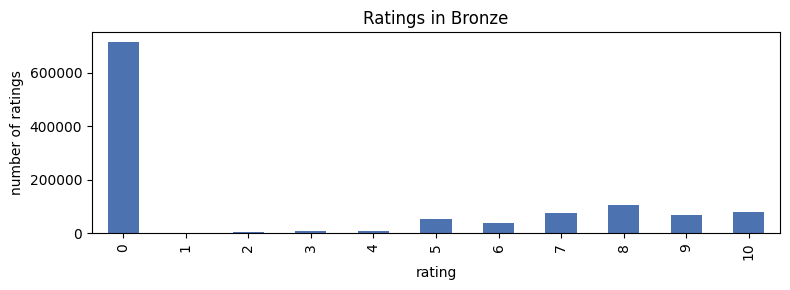

In [7]:
rating_counts = rating_b.value_counts().sort_index()
display(pd.DataFrame({
    "ratings": rating_counts,
    "%": (rating_counts / rating_counts.sum() * 100).round(1),
}).T)

print(f"Ratings equal to 0: {(rating_b == 0).sum():,} ({(rating_b == 0).mean() * 100:.1f}%)")
print(f"Ratings from 1 to 10: {(rating_b > 0).sum():,} ({(rating_b > 0).mean() * 100:.1f}%)")
print(f"Mean of the 1-10 ratings: {rating_b[rating_b > 0].mean():.2f}")

fig, ax = plt.subplots(figsize=(8, 3))
rating_counts.plot.bar(ax=ax, color="#4C72B0")
ax.set_xlabel("rating")
ax.set_ylabel("number of ratings")
ax.set_title("Ratings in Bronze")
plt.tight_layout()
plt.show()

**Found:** 716,109 ratings (62.3%) are 0. A 0 means "no explicit rating", not a bad rating. The 433,671 real ratings (1-10) are mostly high: the mean is 7.6 and 8 is the most common value. **Silver:** remove all ratings of 0.

### 2.3 Distribution of user ages and publication years

User age:


,count,mean,std,min,25%,50%,75%,max
Age,168096.0,34.8,14.4,0.0,24.0,32.0,44.0,244.0


Missing: 110,762 | below 5: 882 | above 100: 366 | median of ages 5-100: 32

Publication year:


,count,mean,std,min,25%,50%,75%,max
Year-Of-Publication,271379.0,1959.8,258.0,0.0,1989.0,1995.0,2000.0,2050.0


Year 0: 4,619 | after 2026: 11 -> [2030, 2037, 2038, 2050]
Years 1-1899: 4


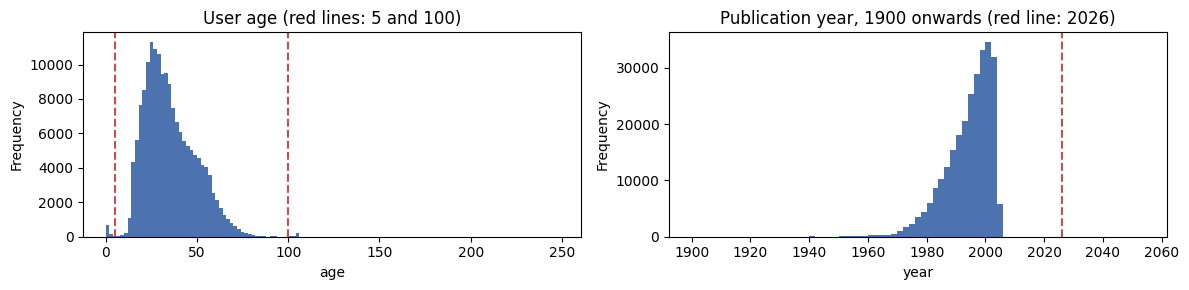

In [8]:
print("User age:")
display(age_b.describe().round(1).to_frame().T)
print(f"Missing: {age_b.isna().sum():,} | below 5: {(age_b < 5).sum():,} | above 100: {(age_b > 100).sum():,} "
      f"| median of ages 5-100: {age_b[age_b.between(5, 100)].median():.0f}")

print("\nPublication year:")
display(year_b.describe().round(1).to_frame().T)
print(f"Year 0: {(year_b == 0).sum():,} | after {CURRENT_YEAR}: {(year_b > CURRENT_YEAR).sum():,} "
      f"-> {sorted(year_b[year_b > CURRENT_YEAR].astype(int).unique().tolist())}")
print(f"Years 1-1899: {year_b.between(1, 1899).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
age_b.dropna().plot.hist(bins=range(0, 250, 2), ax=axes[0], color="#4C72B0")
for limit in (5, 100):
    axes[0].axvline(limit, color="#C44E52", linestyle="--")
axes[0].set_title("User age (red lines: 5 and 100)")
axes[0].set_xlabel("age")
year_b[year_b >= 1900].plot.hist(bins=range(1900, 2055, 2), ax=axes[1], color="#4C72B0")
axes[1].axvline(CURRENT_YEAR, color="#C44E52", linestyle="--")
axes[1].set_title(f"Publication year, 1900 onwards (red line: {CURRENT_YEAR})")
axes[1].set_xlabel("year")
plt.tight_layout()
plt.show()

**Found:** ages go from 0 to 244. 882 ages are below 5, 366 are above 100 and 110,762 are missing. Years go from 0 to 2050. 4,619 years are 0 and 11 are in the future (2030, 2037, 2038, 2050). **Silver:** set ages below 5 or above 100 to missing, then fill all missing ages with the median (32). Set year 0 and future years to missing. Four years are before 1900 (1376, 1378, 1806, 1897). The rule covers only 0 and future years, so I keep them.

### 2.4 Number of ratings per user and per book

,per user (all),per book (all),per user (1-10 only),per book (1-10 only)
count,105283.0,340556.0,77805.0,185973.0
median,1.0,1.0,1.0,1.0
mean,10.9,3.4,5.6,2.3
max,13602.0,2502.0,8524.0,707.0
% with 1 rating,56.2,57.9,58.3,69.7
% with 10+ ratings,12.4,5.4,9.4,3.0


Users and books with at least t ratings (1-10 only):


t,1,2,5,10,20,50
users,77805,32423,14220,7334,3704,1332
books,185973,56352,14535,5645,2179,537


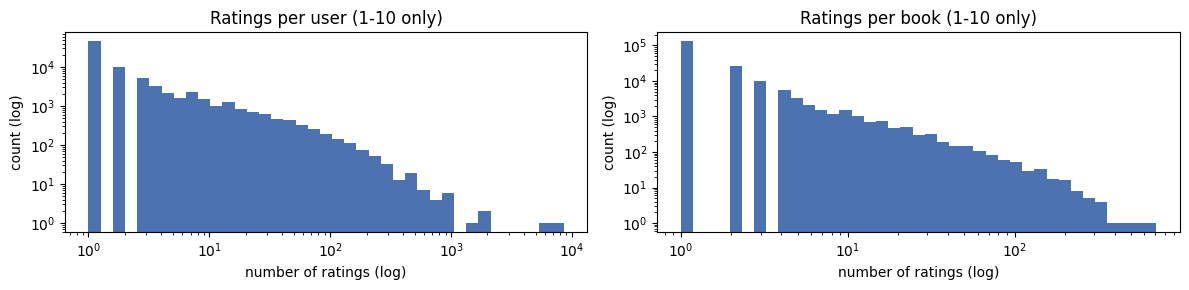

In [9]:
explicit_b = ratings_b[rating_b > 0]
per = {
    "per user (all)": ratings_b.groupby("User-ID").size(),
    "per book (all)": ratings_b.groupby("ISBN").size(),
    "per user (1-10 only)": explicit_b.groupby("User-ID").size(),
    "per book (1-10 only)": explicit_b.groupby("ISBN").size(),
}
display(pd.DataFrame({
    name: {
        "count": len(c),
        "median": c.median(),
        "mean": round(c.mean(), 1),
        "max": c.max(),
        "% with 1 rating": round((c == 1).mean() * 100, 1),
        "% with 10+ ratings": round((c >= 10).mean() * 100, 1),
    }
    for name, c in per.items()
}))

print("Users and books with at least t ratings (1-10 only):")
display(pd.DataFrame([{
    "t": t,
    "users": int((per["per user (1-10 only)"] >= t).sum()),
    "books": int((per["per book (1-10 only)"] >= t).sum()),
} for t in [1, 2, 5, 10, 20, 50]]).set_index("t").T)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, name in zip(axes, ["per user (1-10 only)", "per book (1-10 only)"]):
    c = per[name]
    ax.hist(c, bins=np.logspace(0, np.log10(c.max() + 1), 40), color="#4C72B0")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"Ratings {name}")
    ax.set_xlabel("number of ratings (log)")
    ax.set_ylabel("count (log)")
plt.tight_layout()
plt.show()

**Found:** the median user and the median book have only 1 rating. With ratings 1-10 only, 58.3% of users and 69.7% of books have exactly 1 rating, and only 7,334 users and 5,645 books have 10 or more. Similarity from 1 or 2 ratings is not reliable. **Silver:** keep only users and books with at least 10 ratings (see 3.8).

### 2.5 Matrix sparsity

In [10]:
for label, table in [("all ratings", ratings_b), ("ratings 1-10", explicit_b)]:
    n_users = table["User-ID"].nunique()
    n_books = table["ISBN"].nunique()
    filled = len(table) / (n_users * n_books) * 100
    print(f"{label:12s}: {len(table):,} ratings / ({n_users:,} users x {n_books:,} books) "
          f"= {filled:.4f}% filled -> sparsity {100 - filled:.4f}%")

all ratings : 1,149,780 ratings / (105,283 users x 340,556 books) = 0.0032% filled -> sparsity 99.9968%


ratings 1-10: 433,671 ratings / (77,805 users x 185,973 books) = 0.0030% filled -> sparsity 99.9970%


**Found:** only 0.0032% of all possible user-book pairs have a rating (sparsity 99.9968%). **Silver:** the minimum-ratings filter makes the matrix denser. **Gold:** store the matrix as a sparse matrix.

### 2.6 Extra checks: duplicates, broken links and text

In [11]:
print("Exact duplicate rows (timestamp column ignored):")
for name, table in bronze.items():
    print(f"  {name}: {table.drop(columns='ingestion_timestamp').duplicated().sum():,}")

isbn_key = books_b["ISBN"].str.strip().str.upper()
rating_isbn_key = ratings_b["ISBN"].str.strip().str.upper()
print(f"Books whose ISBN repeats after upper case ('x' vs 'X'): {isbn_key.duplicated().sum():,}")
print(f"Ratings with an ISBN that is not in the books table: {(~rating_isbn_key.isin(isbn_key)).sum():,}")
print(f"Ratings with a user that is not in the users table: {(~ratings_b['User-ID'].isin(users_b['User-ID'])).sum():,}")

parts = users_b["Location"].str.count(",") + 1
print(f"Locations with exactly 3 parts: {(parts == 3).sum():,}; other: {(parts != 3).sum():,}")

for column in ["Book-Title", "Book-Author", "Publisher"]:
    text = books_b[column].fillna("")
    print(f"{column}: HTML codes such as &amp; in {text.str.contains('&[a-z]+;|&#[0-9]+;', regex=True).sum():,} rows, "
          f"extra spaces in {(text != text.str.replace(r'\s+', ' ', regex=True).str.strip()).sum():,} rows, "
          f"all upper case in {(text.str.isupper()).sum():,} rows")

Exact duplicate rows (timestamp column ignored):


  users: 0


  books: 0


  ratings: 0


Books whose ISBN repeats after upper case ('x' vs 'X'): 315
Ratings with an ISBN that is not in the books table: 118,602
Ratings with a user that is not in the users table: 0


Locations with exactly 3 parts: 277,348; other: 1,510


Book-Title: HTML codes such as &amp; in 4,908 rows, extra spaces in 2,549 rows, all upper case in 5,218 rows


Book-Author: HTML codes such as &amp; in 270 rows, extra spaces in 1,333 rows, all upper case in 5,914 rows


Publisher: HTML codes such as &amp; in 15,793 rows, extra spaces in 26 rows, all upper case in 1,146 rows


**Found:** there are no exact duplicate rows, but 315 ISBNs repeat when `x` and `X` are the same. 118,602 ratings use an ISBN that is not in the books table. Titles, authors and publishers have HTML codes (`&amp;`), extra spaces and mixed case. 1,510 locations do not have exactly 3 parts. **Silver:** change ISBNs to upper case before the duplicate check, remove ratings with an unknown book, clean the text, and split locations by their first and last part.

## Step 3: Clean the data and build the Silver layer

Apply the cleaning rules in order. Each cell prints the effect of one rule.

### 3.0 Prepare

Start from the Bronze tables. Give the columns short names. Convert the numeric columns to numbers. Trim the ISBN key and change it to upper case, so that `...x` and `...X` are the same book.

In [12]:
users = users_b.drop(columns="ingestion_timestamp").rename(columns={
    "User-ID": "user_id", "Location": "location", "Age": "age"})
books = books_b.drop(columns="ingestion_timestamp").rename(columns={
    "ISBN": "isbn", "Book-Title": "title", "Book-Author": "author", "Year-Of-Publication": "year",
    "Publisher": "publisher", "Image-URL-S": "image_url_s", "Image-URL-M": "image_url_m", "Image-URL-L": "image_url_l"})
ratings = ratings_b.drop(columns="ingestion_timestamp").rename(columns={
    "User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})

users["user_id"] = users["user_id"].astype(int)
users["age"] = pd.to_numeric(users["age"])        # float, because some ages are missing
books["year"] = pd.to_numeric(books["year"])
ratings["user_id"] = ratings["user_id"].astype(int)
ratings["rating"] = ratings["rating"].astype(int)

books["isbn"] = books["isbn"].str.strip().str.upper()
ratings["isbn"] = ratings["isbn"].str.strip().str.upper()

for name, table in [("users", users), ("books", books), ("ratings", ratings)]:
    print(f"{name}: {table.shape}, types: {dict(table.dtypes.astype(str))}")

users: (278858, 3), types: {'user_id': 'int64', 'location': 'object', 'age': 'float64'}
books: (271379, 8), types: {'isbn': 'object', 'title': 'object', 'author': 'object', 'year': 'int64', 'publisher': 'object', 'image_url_s': 'object', 'image_url_m': 'object', 'image_url_l': 'object'}
ratings: (1149780, 3), types: {'user_id': 'int64', 'isbn': 'object', 'rating': 'int64'}


### 3.1 Remove duplicate rows

Remove exact duplicate rows. Then keep one row for each key: `user_id` for users, `isbn` for books, and (`user_id`, `isbn`) for ratings. If a user rated the same book twice, keep the higher rating, because 0 means "no explicit rating".

In [13]:
before = {"users": len(users), "books": len(books), "ratings": len(ratings)}

users = users.drop_duplicates().drop_duplicates(subset="user_id")
books = books.drop_duplicates().drop_duplicates(subset="isbn")
ratings = (ratings.drop_duplicates()
           .sort_values("rating", ascending=False)
           .drop_duplicates(subset=["user_id", "isbn"])
           .sort_index())

for name, table in [("users", users), ("books", books), ("ratings", ratings)]:
    print(f"{name:8s}: {before[name]:>9,} -> {len(table):>9,} rows ({before[name] - len(table):,} duplicates removed)")

users   :   278,858 ->   278,858 rows (0 duplicates removed)
books   :   271,379 ->   271,064 rows (315 duplicates removed)
ratings : 1,149,780 -> 1,149,780 rows (0 duplicates removed)


### 3.2 Remove ratings of 0

A rating of 0 means "no explicit rating". Keep only ratings from 1 to 10.

In [14]:
before = len(ratings)
ratings = ratings[ratings["rating"].between(1, 10)]
print(f"ratings: {before:,} -> {len(ratings):,} rows ({before - len(ratings):,} removed)")
print("Ratings left:", ratings["rating"].value_counts().sort_index().to_dict())

ratings: 1,149,780 -> 433,671 rows (716,109 removed)
Ratings left: {1: 1770, 2: 2759, 3: 5996, 4: 8904, 5: 50974, 6: 36924, 7: 76457, 8: 103736, 9: 67541, 10: 78610}


### 3.3 Fix user ages

Set ages below 5 or above 100 to missing. Then fill all missing ages with the median age.

In [15]:
bad_age = (users["age"] < 5) | (users["age"] > 100)
print(f"Ages below 5 or above 100, set to missing: {bad_age.sum():,}")
users.loc[bad_age, "age"] = np.nan

median_age = users["age"].median()
missing_age = users["age"].isna().sum()
users["age"] = users["age"].fillna(median_age).round().astype(int)
print(f"Missing ages filled with the median ({median_age:.0f}): {missing_age:,}")
display(users["age"].describe().round(1).to_frame().T)

Ages below 5 or above 100, set to missing: 1,248
Missing ages filled with the median (32): 112,010


,count,mean,std,min,25%,50%,75%,max
age,278858.0,33.6,10.6,5.0,29.0,32.0,35.0,100.0


### 3.4 Split the user location

`Location` has the form "city, state, country". The first part is the city and the last part is the country. All parts between them are the state.

In [16]:
def split_location(text):
    parts = [part.strip() for part in str(text).split(",")]
    city = parts[0]
    state = ", ".join(parts[1:-1]) if len(parts) >= 3 else ""
    country = parts[-1] if len(parts) >= 2 else ""
    return city, state, country

users[["city", "state", "country"]] = users["location"].apply(split_location).tolist()

examples = users["location"].str.count(",").ne(2)
display(pd.concat([users[~examples].head(3), users[examples].head(3)])[["user_id", "location", "city", "state", "country"]])
users = users.drop(columns="location")

,user_id,location,city,state,country
0,1,"nyc, new york, usa",nyc,new york,usa
1,2,"stockton, california, usa",stockton,california,usa
2,3,"moscow, yukon territory, russia",moscow,yukon territory,russia
435,436,"ivanhoe, melbourne, victoria, australia",ivanhoe,"melbourne, victoria",australia
814,815,"davis bay, sechelt, british columbia, canada",davis bay,"sechelt, british columbia",canada
840,841,"saint charles, mo, missouri, usa",saint charles,"mo, missouri",usa


### 3.5 Fix publication years

Set year 0 and years after the current year to missing.

In [17]:
year_zero = books["year"] == 0
year_future = books["year"] > CURRENT_YEAR
print(f"Year 0: {year_zero.sum():,} | after {CURRENT_YEAR}: {year_future.sum():,} -> set to missing")
books.loc[year_zero | year_future, "year"] = np.nan
books["year"] = books["year"].astype("Int64")
display(books["year"].describe().round(1).to_frame().T)

Year 0: 4,612 | after 2026: 11 -> set to missing


,count,mean,std,min,25%,50%,75%,max
year,266441.0,1993.7,8.3,1376.0,1989.0,1996.0,2000.0,2026.0


### 3.6 Clean the text columns

- Change HTML codes such as `&amp;` back to normal characters.
- Remove extra spaces at the start, at the end and between words.
- Use one case style. Titles, authors and publishers use title case (first letter of each word in upper case). The location columns use lower case.
- Write author initials in one style: `J.R.R. Tolkien` becomes `J. R. R. Tolkien`, the same as most other rows.
- Change placeholder locations such as `n/a` to missing.
- Drop the three image-URL columns. The recommender does not use them.

`str.title()` changes "Sorcerer's" to "Sorcerer'S" and "1st" to "1St". The `title_case` function below does not have these problems. It also keeps Roman numerals such as `III` in upper case.

In [18]:
WORD = re.compile(r"[A-Za-z0-9]+(?:'[A-Za-z]+)?")
ROMAN = re.compile(r"(?=[IVX])X{0,3}(IX|IV|V?I{0,3})")
INITIAL = re.compile(r"\b([A-Z])\.(?=[A-Z])")
LOCATION_PLACEHOLDERS = {"", "n/a", "na", "none", "null", "?", "-", "x", "unknown"}

def clean_text(series):
    series = series.map(html.unescape, na_action="ignore")
    return series.str.replace(r"\s+", " ", regex=True).str.strip()

def title_case(series):
    # Keep Roman numerals such as "III" in upper case. "1st" stays "1st".
    def fix(match):
        word = match.group(0)
        return word if ROMAN.fullmatch(word) else word.capitalize()
    return series.str.replace(WORD, fix, regex=True)

old_books = books[["title", "author", "publisher"]].copy()
for column in ["title", "author", "publisher"]:
    books[column] = title_case(clean_text(books[column]))
books["author"] = books["author"].str.replace(INITIAL, r"\1. ", regex=True)

for column in ["city", "state", "country"]:
    users[column] = clean_text(users[column]).str.lower().str.strip(" .\"'")
    users.loc[users[column].isin(LOCATION_PLACEHOLDERS), column] = np.nan

books = books.drop(columns=["image_url_s", "image_url_m", "image_url_l"])

changed = (old_books.fillna("") != books[["title", "author", "publisher"]].fillna("")).any(axis=1)
print(f"Books with changed text: {changed.sum():,}")
sample = old_books[changed].sample(6, random_state=1)
display(pd.DataFrame({"title before": sample["title"], "title after": books.loc[sample.index, "title"],
                      "author before": sample["author"], "author after": books.loc[sample.index, "author"]}))
print("Missing location parts:", users[["city", "state", "country"]].isna().sum().to_dict())
print("Top countries:", users["country"].value_counts().head(8).to_dict())
print("Book columns now:", list(books.columns))

Books with changed text: 178,424


,title before,title after,author before,author after
220699,Color Crazy: A Guide to Understanding the Colors in Lour Life (Cos...,Color Crazy: A Guide To Understanding The Colors In Lour Life (Cos...,Lori Reid,Lori Reid
204265,Flying Fox in a Freedom Tree,Flying Fox In A Freedom Tree,Albert Wendt,Albert Wendt
88895,"MacKenzie's Mission (Silhouette Intimate Moments, No 445)","Mackenzie's Mission (Silhouette Intimate Moments, No 445)",Linda Howard,Linda Howard
929,The Great Depression : America 1929-1941,The Great Depression : America 1929-1941,ROBERT S. MCELVAINE,Robert S. Mcelvaine
200849,Sight of a Stranger (Harlequin Romance),Sight Of A Stranger (Harlequin Romance),Sandra Field,Sandra Field
157792,STREETBIRD,Streetbird,Janwillem Van De Wetering,Janwillem Van De Wetering


Missing location parts: {'city': 682, 'state': 17070, 'country': 4612}
Top countries: {'usa': 139712, 'canada': 21658, 'united kingdom': 18557, 'germany': 17073, 'spain': 13258, 'australia': 11785, 'italy': 11271, 'france': 3487}
Book columns now: ['isbn', 'title', 'author', 'year', 'publisher']


### 3.7 Keep only ratings with a known user and a known book

In [19]:
before = len(ratings)
known_user = ratings["user_id"].isin(users["user_id"])
known_book = ratings["isbn"].isin(books["isbn"])
print(f"Ratings with an unknown user: {(~known_user).sum():,}")
print(f"Ratings with an unknown book: {(~known_book).sum():,}")
ratings = ratings[known_user & known_book]
print(f"ratings: {before:,} -> {len(ratings):,} rows")

Ratings with an unknown user: 0
Ratings with an unknown book: 49,818
ratings: 433,671 -> 383,853 rows


### 3.8 Keep only active users and popular books

Remove users and books with fewer than *t* ratings. One pass is not enough: when a book goes, some users drop below *t*, and the other way around. So the function repeats the filter until no row changes. After this step, every user and every book has at least *t* ratings.

The table compares some values of *t*.

In [20]:
def keep_active(ratings, min_ratings):
    rounds = 0
    while True:
        rounds += 1
        user_count = ratings["user_id"].map(ratings["user_id"].value_counts())
        book_count = ratings["isbn"].map(ratings["isbn"].value_counts())
        keep = (user_count >= min_ratings) & (book_count >= min_ratings)
        if keep.all():
            return ratings, rounds
        ratings = ratings[keep]

candidates = []
for t in [3, 5, 10, 15, 20]:
    kept, rounds = keep_active(ratings, t)
    n_users, n_books = kept["user_id"].nunique(), kept["isbn"].nunique()
    candidates.append({
        "t": t, "rounds": rounds, "ratings": len(kept), "users": n_users, "books": n_books,
        "filled %": round(len(kept) / (n_users * n_books) * 100, 3) if len(kept) else 0.0,
        "median ratings per book": float(kept["isbn"].value_counts().median()) if len(kept) else 0.0,
    })
display(pd.DataFrame(candidates).set_index("t"))

,rounds,ratings,users,books,filled %,median ratings per book
t,,,,,,
3,10,183649,14523,22667,0.056,4.0
5,17,115332,6858,9092,0.185,8.0
10,13,41469,1820,2030,1.122,15.0
15,14,0,0,0,0.000,0.0
20,7,0,0,0,0.000,0.0


**Threshold: at least 10 ratings for each user and each book.** Reasons:

1. The EDA (2.4) shows that most users and books have only 1 rating. Similarity from so few ratings is noise.
2. With *t* = 10, each book has at least 10 ratings (median 15), and 1.12% of the matrix is filled. With *t* = 5, only 0.19% is filled and the median book has 8 ratings.
3. With *t* = 15 or more, the repeated filter removes all the data.
4. The assignment also suggests 10.

The cost: only 1,820 users and 2,030 books stay. The recommender works only for these active users and popular books.

In [21]:
MIN_RATINGS = 10

before = len(ratings)
ratings, rounds = keep_active(ratings, MIN_RATINGS)
users = users[users["user_id"].isin(ratings["user_id"])]
books = books[books["isbn"].isin(ratings["isbn"])]

print(f"Threshold: at least {MIN_RATINGS} ratings for each user and each book ({rounds} rounds)")
print(f"ratings: {before:,} -> {len(ratings):,} | users: {len(users):,} | books: {len(books):,}")

Threshold: at least 10 ratings for each user and each book (13 rounds)
ratings: 383,853 -> 41,469 | users: 1,820 | books: 2,030


### 3.9 Save the Silver tables and check them

In [22]:
users = users.reset_index(drop=True)
books = books.reset_index(drop=True)
ratings = ratings.reset_index(drop=True)

users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)

# Checks: each rule from Step 3 must hold in the saved tables.
assert not users["user_id"].duplicated().any()
assert not books["isbn"].duplicated().any()
assert not ratings.duplicated(subset=["user_id", "isbn"]).any()
assert ratings["rating"].between(1, 10).all()
assert users["age"].between(5, 100).all() and users["age"].notna().all()
assert {"city", "state", "country"} <= set(users.columns) and "location" not in users.columns
assert books["year"].dropna().between(1, CURRENT_YEAR).all()
assert not any(column.startswith("image_url") for column in books.columns)
assert ratings["user_id"].isin(users["user_id"]).all() and ratings["isbn"].isin(books["isbn"]).all()
assert (ratings["user_id"].value_counts() >= MIN_RATINGS).all()
assert (ratings["isbn"].value_counts() >= MIN_RATINGS).all()
print("All Silver checks passed.\n")

display(pd.DataFrame({
    "Bronze rows": [len(users_b), len(books_b), len(ratings_b)],
    "Silver rows": [len(users), len(books), len(ratings)],
    "Silver columns": [list(users.columns), list(books.columns), list(ratings.columns)],
}, index=["users", "books", "ratings"]))
display(users.head(3), books.head(3), ratings.head(3))

All Silver checks passed.



,Bronze rows,Silver rows,Silver columns
users,278858,1820,"[user_id, age, city, state, country]"
books,271379,2030,"[isbn, title, author, year, publisher]"
ratings,1149780,41469,"[user_id, isbn, rating]"


,user_id,age,city,state,country
0,243,32,arden hills,minnesota,usa
1,254,24,minneapolis,minnesota,usa
2,638,20,san diego,california,usa


,isbn,title,author,year,publisher
0,0440234743,The Testament,John Grisham,1999,Dell
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison,1994,Plume
2,0971880107,Wild Animus,Rich Shapero,2004,Too Far


,user_id,isbn,rating
0,277427,002542730X,10
1,277427,0060542128,7
2,277427,0061009059,9


## Step 4: Build the Gold layer

Read the Silver tables back and make the model-ready data:

1. A sparse user-book rating matrix. Each row is a user and each column is a book. Most cells are empty, so a sparse matrix stores only the filled cells.
2. The index files that link matrix rows to `user_id` and matrix columns to `isbn`.
3. A book lookup table (book id, title, author), so that the recommender can show titles.
4. User and book aggregates: average rating and number of ratings.

In [23]:
users_s = pd.read_parquet("silver/users.parquet")
books_s = pd.read_parquet("silver/books.parquet")
ratings_s = pd.read_parquet("silver/ratings.parquet")

user_ids = np.sort(ratings_s["user_id"].unique())
isbns = np.sort(ratings_s["isbn"].unique())
user_pos = pd.Series(np.arange(len(user_ids)), index=user_ids)
book_pos = pd.Series(np.arange(len(isbns)), index=isbns)

rating_matrix = sp.csr_matrix(
    (ratings_s["rating"].to_numpy(dtype=np.float32),
     (user_pos[ratings_s["user_id"]].to_numpy(), book_pos[ratings_s["isbn"]].to_numpy())),
    shape=(len(user_ids), len(isbns)),
)
sp.save_npz("gold/user_book_matrix.npz", rating_matrix)

user_index = pd.DataFrame({"user_idx": np.arange(len(user_ids)), "user_id": user_ids})
user_index.to_parquet("gold/user_index.parquet", index=False)

book_lookup = (pd.DataFrame({"book_idx": np.arange(len(isbns)), "isbn": isbns})
               .merge(books_s[["isbn", "title", "author"]], on="isbn", how="left"))
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

user_aggregates = (ratings_s.groupby("user_id")["rating"]
                   .agg(avg_rating="mean", n_ratings="size").round(2).reset_index())
user_aggregates.to_parquet("gold/user_aggregates.parquet", index=False)

book_aggregates = (ratings_s.groupby("isbn")["rating"]
                   .agg(avg_rating="mean", n_ratings="size").round(2).reset_index()
                   .merge(books_s[["isbn", "title", "author"]], on="isbn", how="left"))
book_aggregates.to_parquet("gold/book_aggregates.parquet", index=False)

filled = rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1]) * 100
sparse_mb = (rating_matrix.data.nbytes + rating_matrix.indices.nbytes + rating_matrix.indptr.nbytes) / 1e6
dense_mb = rating_matrix.shape[0] * rating_matrix.shape[1] * 4 / 1e6
print(f"Rating matrix: {rating_matrix.shape[0]:,} users x {rating_matrix.shape[1]:,} books, "
      f"{rating_matrix.nnz:,} ratings, {filled:.2f}% filled")
print(f"Memory: sparse {sparse_mb:.2f} MB, dense would need {dense_mb:.1f} MB")
print("Gold files:", sorted(os.listdir("gold")))

display(book_lookup.head(3))
print("Most rated books:")
display(book_aggregates.sort_values("n_ratings", ascending=False).head(5))
print("Most active users:")
display(user_aggregates.sort_values("n_ratings", ascending=False).head(5))

Rating matrix: 1,820 users x 2,030 books, 41,469 ratings, 1.12% filled
Memory: sparse 0.34 MB, dense would need 14.8 MB
Gold files: ['book_aggregates.parquet', 'book_lookup.parquet', 'user_aggregates.parquet', 'user_book_matrix.npz', 'user_index.parquet']


,book_idx,isbn,title,author
0,0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald
1,1,0020442203,"Lion, The Witch And The Wardrobe",C. S. Lewis
2,2,002542730X,Politically Correct Bedtime Stories: Modern Tales For Our Life And...,James Finn Garner


Most rated books:


,isbn,avg_rating,n_ratings,title,author
281,0316666343,8.24,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.61,177,The Da Vinci Code,Dan Brown
205,0312195516,8.49,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.66,125,The Secret Life Of Bees,Sue Monk Kidd
1520,059035342X,9.04,119,Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)),J. K. Rowling


Most active users:


,user_id,avg_rating,n_ratings
59,11676,7.71,954
86,16795,7.82,242
607,95359,8.01,195
668,104636,8.73,187
737,114368,6.78,176


## Step 5: Build the recommender (item-based collaborative filtering)

Two books are similar when the same users give them similar ratings. Each book is a vector of ratings from all users. Cosine similarity compares two such vectors.

### 5.1 Load the matrix from the Gold layer

Load the user-book matrix and transpose it. Now each row is a book and each column is a user.

In [24]:
matrix = sp.load_npz("gold/user_book_matrix.npz").tocsr()            # rows = users, columns = books
book_lookup = pd.read_parquet("gold/book_lookup.parquet").sort_values("book_idx").reset_index(drop=True)
user_index = pd.read_parquet("gold/user_index.parquet")

book_user = matrix.T.tocsr()                                          # rows = books, columns = users
user_row = pd.Series(user_index["user_idx"].to_numpy(), index=user_index["user_id"].to_numpy())
assert (book_lookup["book_idx"].to_numpy() == np.arange(book_user.shape[0])).all()

print(f"user x book matrix: {matrix.shape} -> book x user matrix: {book_user.shape}")

user x book matrix: (1820, 2030) -> book x user matrix: (2030, 1820)


### 5.2 Cosine similarity between books

`NearestNeighbors` with the cosine metric works on the sparse matrix directly. It returns the cosine distance, so similarity = 1 - distance. The check below compares it with `cosine_similarity`.

In [25]:
knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(book_user)

distance, neighbour = knn.kneighbors(book_user[0], n_neighbors=2)
print(f"Book 0 and its nearest book: 1 - distance = {1 - distance[0, 1]:.6f}, "
      f"cosine_similarity = {cosine_similarity(book_user[0], book_user[neighbour[0, 1]])[0, 0]:.6f}")

Book 0 and its nearest book: 1 - distance = 0.269862, cosine_similarity = 0.269862


### 5.3 Find the 10 most similar books for a title

One book can have more than one ISBN (for example, hardcover and paperback), often with a different note in brackets. The function uses the ISBN with the most ratings. It also removes other editions of a book from the result. Two titles are editions of the same book when they are equal before the first `(` or ` : `.

In [26]:
book_popularity = np.diff(book_user.indptr)                     # number of ratings for each book
title_key = book_lookup["title"].fillna("").str.lower()
edition_key = title_key.str.split("(", n=1).str[0].str.split(" : ", n=1).str[0].str.strip()

def find_book(title):
    key = title.strip().lower()
    matches = np.flatnonzero(title_key == key)
    if len(matches) == 0:
        matches = np.flatnonzero(title_key.str.contains(key, regex=False))
    if len(matches) == 0:
        raise ValueError(f"No book in the Gold layer matches {title!r}")
    return int(matches[np.argmax(book_popularity[matches])])

def similar_books(title, n=10):
    book = find_book(title)
    distance, neighbour = knn.kneighbors(book_user[book], n_neighbors=min(n + 30, book_user.shape[0]))
    seen = {edition_key[book]}
    rows = []
    for d, j in zip(distance[0], neighbour[0]):
        if j == book or edition_key[j] in seen:
            continue
        seen.add(edition_key[j])
        rows.append({"title": book_lookup.at[j, "title"], "author": book_lookup.at[j, "author"],
                     "similarity": round(1 - d, 3)})
        if len(rows) == n:
            break
    print(f"Books similar to: {book_lookup.at[book, 'title']} by {book_lookup.at[book, 'author']} "
          f"(ISBN {book_lookup.at[book, 'isbn']}, {book_popularity[book]} ratings)")
    return pd.DataFrame(rows, index=range(1, len(rows) + 1))

In [27]:
display(similar_books("Harry Potter and the Sorcerer's Stone"))

Books similar to: Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) by J. K. Rowling (ISBN 059035342X, 119 ratings)


,title,author,similarity
1,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,0.411
2,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,0.316
3,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,0.254
4,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,0.243
5,Fried Green Tomatoes At The Whistle Stop Cafe,Fannie Flagg,0.189
6,Love Story,Erich Segal,0.170
7,Anne Of Green Gables (Anne Of Green Gables Novels (Paperback)),L. M. Montgomery,0.163
8,Anne Of Ingleside (Anne Of Green Gables Novels (Paperback)),L. M. Montgomery,0.156
9,Like Water For Chocolate: A Novel In Monthly Installments With Rec...,Laura Esquivel,0.155
10,"Blood Of The Fold (Sword Of Truth, Book 3)",Terry Goodkind,0.154


In [28]:
display(similar_books("The Da Vinci Code"))

Books similar to: The Da Vinci Code by Dan Brown (ISBN 0385504209, 177 ratings)


,title,author,similarity
1,Angels & Demons,Dan Brown,0.240
2,The Lovely Bones: A Novel,Alice Sebold,0.178
3,The Narrows: A Novel,Michael Connelly,0.176
4,Middlesex: A Novel,Jeffrey Eugenides,0.175
5,Sea Glass: A Novel,Anita Shreve,0.162
6,No Second Chance,Harlan Coben,0.160
7,The Face,Dean Koontz,0.158
8,Nights In Rodanthe,Nicholas Sparks,0.156
9,The Secret Life Of Bees,Sue Monk Kidd,0.156
10,The Conspiracy Club,Jonathan Kellerman,0.151


### 5.4 Recommend books for a user

`recommend(user_id, n=10)` does these steps:

1. Find the books that the user rated highly (8 or more). If the user has no such book, use the books rated at or above the user's own average.
2. For each of these books, get the 30 most similar books.
3. Give each candidate a score: the sum of (similarity × the user's rating of the source book).
4. Remove the books that the user already rated, and other editions of them.
5. Return the top `n` titles by score.

In [29]:
HIGH_RATING = 8
NEIGHBOURS_PER_BOOK = 30

def user_ratings(user_id):
    if user_id not in user_row.index:
        raise ValueError(f"User {user_id} is not in the Gold matrix")
    row = user_row[user_id]
    start, end = matrix.indptr[row], matrix.indptr[row + 1]
    return matrix.indices[start:end], matrix.data[start:end]

def recommend(user_id, n=10):
    rated, given = user_ratings(user_id)
    liked = given >= HIGH_RATING
    if not liked.any():
        liked = given >= given.mean()
    sources, source_ratings = rated[liked], given[liked]

    distance, neighbour = knn.kneighbors(book_user[sources], n_neighbors=NEIGHBOURS_PER_BOOK + 1)
    scores = defaultdict(float)
    for rating, d_row, j_row in zip(source_ratings, distance, neighbour):
        for d, j in zip(d_row, j_row):
            scores[j] += (1 - d) * rating

    already_read = set(rated)
    seen_books = set(edition_key[rated])
    rows = []
    for j, score in sorted(scores.items(), key=lambda item: item[1], reverse=True):
        if j in already_read or edition_key[j] in seen_books:
            continue
        seen_books.add(edition_key[j])
        rows.append({"isbn": book_lookup.at[j, "isbn"], "title": book_lookup.at[j, "title"],
                     "author": book_lookup.at[j, "author"], "score": round(score, 2)})
        if len(rows) == n:
            break
    return pd.DataFrame(rows, index=range(1, len(rows) + 1))

## Step 6: Demo and sanity check

For each user, the table shows the books the user rated highly (left) next to the recommendations (right). The number after a rated title is the user's rating. The number after a recommended title is its score. For equal ratings, the left column shows the most rated books first.

The cell also checks that no recommendation is a book the user already rated.

In [30]:
def short(text, width=58):
    text = str(text)
    return text if len(text) <= width else text[: width - 3] + "..."

def show_user(user_id, n=10):
    rated, given = user_ratings(user_id)
    # Highest rating first. For equal ratings, show the most rated books first.
    history = (pd.DataFrame({"book_idx": rated, "rating": given.astype(int), "popularity": book_popularity[rated]})
               .merge(book_lookup, on="book_idx")
               .sort_values(["rating", "popularity"], ascending=[False, False]))
    liked = history[history["rating"] >= HIGH_RATING]
    liked_once = liked[~edition_key[liked["book_idx"]].duplicated().to_numpy()]   # one row per book
    recs = recommend(user_id, n=n)

    # Sanity checks: n results, and no book that the user already rated.
    assert len(recs) == n
    assert not set(recs["isbn"]) & set(history["isbn"])

    left = [f"{short(t)} ({r})" for t, r in zip(liked_once["title"], liked_once["rating"])][:n]
    right = [f"{short(t)} ({s:.2f})" for t, s in zip(recs["title"], recs["score"])]
    size = max(len(left), len(right))
    profile = users_s.set_index("user_id").loc[user_id]
    country = profile["country"] if isinstance(profile["country"], str) else "unknown"
    print(f"User {user_id} | age {profile['age']} | country {country} | "
          f"{len(history)} ratings, {len(liked)} rated {HIGH_RATING}+ (left column shows up to {n})")
    display(pd.DataFrame({
        "Rated highly by the user (rating)": left + [""] * (size - len(left)),
        "Recommended (score)": right + [""] * (size - len(right)),
    }, index=range(1, size + 1)))

### 6.1 Four users with different tastes

I chose four users with clear and different tastes, so that a reader can check the output by eye. Section 6.2 checks all users, not only these four.

In [31]:
demo_users = [259901, 125519, 274301, 14456]

for user_id in demo_users:
    show_user(user_id)

User 259901 | age 32 | country canada | 26 ratings, 17 rated 8+ (left column shows up to 10)

,Rated highly by the user (rating),Recommended (score)
1,"The Fellowship Of The Ring (The Lord Of The Rings, Part 1) (10)",The Dark Half (17.40)
2,The Green Mile (10),The Tommyknockers (17.02)
3,"The Return Of The King (The Lord Of The Rings, Part 3) (10)","The Drawing Of The Three (The Dark Tower, Book 2) (15.35)"
4,Dune (Remembering Tomorrow) (10),Rose Madder (14.14)
5,The Eyes Of The Dragon (10),Four Past Midnight (10.41)
6,"House Atreides (Dune: House Trilogy, Book 1) (10)",Dreamcatcher (10.41)
7,"Wizard And Glass (The Dark Tower, Book 4) (10)","The Two Towers (The Lord Of The Rings, Part 2) (10.29)"
8,Insomnia (9),Desperation (10.13)
9,Needful Things (9),Pet Sematary (10.10)
10,The Talisman (9),The Hobbit : The Enchanting Prelude To The Lord Of The ... (9.64)


User 125519 | age 40 | country usa | 44 ratings, 40 rated 8+ (left column shows up to 10)


,Rated highly by the user (rating),Recommended (score)
1,The Firm (10),Mixed Blessings (13.84)
2,The Pelican Brief (10),The Runaway Jury (13.34)
3,1st To Die: A Novel (10),A Time To Kill (12.91)
4,The Client (10),Cat & Mouse (Alex Cross Novels) (12.63)
5,Chicken Soup For The Soul (Chicken Soup For The Soul) (10),I'll Be Seeing You (12.18)
6,Cradle And All (10),The Rainmaker (11.42)
7,Night (10),My Gal Sunday (11.39)
8,Bridget Jones's Diary (10),The Anastasia Syndrome (10.79)
9,Who Moved My Cheese? An Amazing Way To Deal With Change... (10),Violets Are Blue (10.49)
10,No Second Chance (10),You Belong To Me (10.49)


User 274301 | age 41 | country australia | 54 ratings, 38 rated 8+ (left column shows up to 10)


,Rated highly by the user (rating),Recommended (score)
1,Red Dragon (10),F Is For Fugitive (Kinsey Millhone Mysteries (Paperback)) (34.23)
2,A Is For Alibi (Kinsey Millhone Mysteries (Paperback)) (10),H Is For Homicide (Kinsey Millhone Mysteries (Paperback)) (33.77)
3,Silence Of The Lambs (10),J Is For Judgment (33.15)
4,B Is For Burglar (Kinsey Millhone Mysteries (Paperback)) (10),G Is For Gumshoe (Kinsey Millhone Mysteries (Paperback)) (31.20)
5,Angela's Ashes: A Memoir (10),The Green Mile: Coffey's Hands (Green Mile Series) (23.39)
6,C Is For Corpse (Kinsey Millhone Mysteries (Paperback)) (10),M Is For Malice (21.10)
7,I Is For Innocent (10),The Green Mile: Coffey On The Mile (Green Mile Series) (19.66)
8,D Is For Deadbeat (Kinsey Millhone Mysteries (Paperback)) (10),The Clinic (Alex Delaware Novels (Paperback)) (18.45)
9,E Is For Evidence: A Kinsey Millhone Mystery (Kinsey Mi... (10),The Ritual Bath (Peter Decker & Rina Lazarus Novels (Pa... (15.06)
10,Tara Road (10),"The Web (Alex Delaware Series, No. 10) (14.75)"


User 14456 | age 27 | country canada | 26 ratings, 24 rated 8+ (left column shows up to 10)

,Rated highly by the user (rating),Recommended (score)
1,Harry Potter And The Prisoner Of Azkaban (Book 3) (10),The Authoritative Calvin And Hobbes (Calvin And Hobbes) (34.78)
2,Harry Potter And The Chamber Of Secrets (Book 2) (10),The Calvin And Hobbes Tenth Anniversary Book (32.52)
3,Harry Potter And The Goblet Of Fire (Book 4) (10),The Indispensable Calvin And Hobbes (30.25)
4,"The Vampire Lestat (Vampire Chronicles, Book II) (10)",Harry Potter And The Sorcerer's Stone (Book 1) (20.44)
5,Weirdos From Another Planet! (10),Still Pumped From Using The Mouse (15.13)
6,Homicidal Psycho Jungle Cat: A Calvin And Hobbes Collec... (10),Harry Potter And The Order Of The Phoenix (Book 5) (14.68)
7,Calvin And Hobbes (10),"The Return Of The King (The Lord Of The Rings, Part 3) (12.04)"
8,"The Vampire Armand : The Vampire Chronicles (Rice, Anne... (10)",Love You Forever (11.25)
9,Yukon Ho! (10),"The Fellowship Of The Ring (The Lord Of The Rings, Part 1) (10.61)"
10,Scientific Progress Goes 'Boink': A Calvin And Hobbes C... (10),Dilbert Fugitive From The Cubicle Police (10.08)


**Result:** the recommendations follow each user's taste.

- User 259901 likes Tolkien, Stephen King and *Dune*. The recommendations are other Stephen King books and the rest of *The Lord of the Rings*.
- User 125519 likes John Grisham and James Patterson. The recommendations are more Grisham and Patterson, plus Mary Higgins Clark.
- User 274301 likes the Kinsey Millhone mysteries by Sue Grafton. The recommendations are the next books in that series, parts of *The Green Mile* and other crime novels.
- User 14456 likes *Calvin and Hobbes* and *Harry Potter*. The recommendations are more *Calvin and Hobbes*, the missing *Harry Potter* books, *The Lord of the Rings* and *Dilbert*.

Some recommendations fit less well, for example *Mixed Blessings* by Danielle Steel for user 125519. A user who likes many different books gets a mix of these tastes.

### 6.2 Sanity check on all users

A good recommender follows the user's taste. A simple sign of this is the author. For each user, count how many of the 10 recommended books are by an author that the user rated 8 or more. Compare this with 10 random books that the user did not rate.

In [32]:
rng = np.random.default_rng(42)
all_books = np.arange(book_user.shape[0])
book_author = book_lookup["author"].fillna("").str.lower().to_numpy()

rows = []
for user_id in user_index["user_id"]:
    rated, given = user_ratings(user_id)
    liked_authors = set(book_author[rated[given >= HIGH_RATING]])
    if not liked_authors:
        continue
    recs = recommend(user_id, n=10)
    assert len(recs) == 10 and not set(recs["isbn"]) & set(book_lookup.loc[rated, "isbn"])
    random_books = rng.choice(np.setdiff1d(all_books, rated), size=10, replace=False)
    rows.append({
        "recommended": recs["author"].fillna("").str.lower().isin(liked_authors).mean(),
        "random": np.isin(book_author[random_books], list(liked_authors)).mean(),
    })

check = pd.DataFrame(rows)
print(f"Users checked: {len(check):,} (every user with at least one rating of {HIGH_RATING}+)")
print(f"All of them got 10 recommendations, and none of the recommendations was a book they had rated.")
print(f"Share of books by an author the user rated {HIGH_RATING}+: "
      f"recommended {check['recommended'].mean():.1%}, random {check['random'].mean():.1%}")

Users checked: 1,804 (every user with at least one rating of 8+)
All of them got 10 recommendations, and none of the recommendations was a book they had rated.
Share of books by an author the user rated 8+: recommended 50.0%, random 4.5%


**Result:** for all 1,804 users, 50.0% of the recommended books are by an author that the user rated 8 or more. For random books, the share is 4.5%. So the recommender follows the user's taste. This also shows a limit: item-based filtering often suggests more books by authors that the user already knows, and fewer new authors.

## Requirement checklist

| Requirement | Section | Result |
|---|---|---|
| Create `bronze/`, `silver/`, `gold/` | Step 1 | Folders created |
| Load the raw files as they are; handle `;` and non-UTF-8 text | Step 1 | `sep=";"`, `encoding="latin-1"`, `escapechar`, all values kept as text |
| Add `ingestion_timestamp`; save Bronze as Parquet; no cleaning | Step 1 | 3 Parquet files: 278,858 users, 271,379 books, 1,149,780 ratings |
| EDA: shape, data types, missing values | 2.1 | Only `Age` has missing values (39.7%) |
| EDA: rating distribution and number of 0 ratings | 2.2 | 62.3% of ratings are 0 |
| EDA: ages and publication years | 2.3 | Ages 0-244, years 0-2050 |
| EDA: ratings per user and per book | 2.4 | Median 1 for both |
| EDA: matrix sparsity | 2.5 | 99.9968% empty |
| One finding line and Silver action for each EDA item | 2.1-2.6 | Done |
| Remove duplicate rows | 3.1 | 315 duplicate books removed |
| Remove ratings of 0 | 3.2 | 716,109 removed |
| Fix ages: below 5 or above 100 to missing, fill with median | 3.3 | 1,248 set to missing, 112,010 filled with 32 |
| Split location into city, state, country | 3.4 | Done |
| Fix years: 0 or future to missing | 3.5 | 4,612 + 11 set to missing |
| Clean text: spaces, case; drop image-URL columns | 3.6 | Done |
| Keep ratings with a known user and book | 3.7 | 49,818 removed |
| Minimum number of ratings: choose, state, justify | 3.8 | 10, with the reasons |
| Gold: sparse user-book rating matrix | Step 4 | `user_book_matrix.npz`, 1,820 × 2,030 |
| Gold: book lookup table (book id, title, author) | Step 4 | `book_lookup.parquet` |
| Gold: user and book aggregates (average, count) | Step 4 | `user_aggregates.parquet`, `book_aggregates.parquet` |
| Load the matrix from Gold; books as rows, users as columns | 5.1 | 2,030 × 1,820 |
| Cosine similarity with `NearestNeighbors` | 5.2 | Checked against `cosine_similarity` |
| Function: title → 10 most similar books | 5.3 | `similar_books(title)` |
| `recommend(user_id, n=10)` as described | 5.4 | Done |
| Demo for at least 3 users, liked books next to recommendations | 6.1 | 4 users |